# 멀티모달 RAG 전체 파이프라인

## 0. 환경 설정
### 0-1. 라이브러리 임포트 · 프로젝트 경로 · API 키 로드

In [1]:
import os, re, time, uuid, pickle, base64
from pathlib import Path
from collections import Counter

from dotenv import load_dotenv
from IPython.display import Image, display

# 프로젝트 루트: requirements.txt 가 있는 폴더를 위로 올라가며 찾는다 (notebooks/ 에서 실행해도 동작)
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists()),
    Path.cwd(),
)
load_dotenv(PROJECT_ROOT / ".env")

openai_api_key = os.getenv("OPENAI_API_KEY")
if not openai_api_key:
    raise ValueError("환경변수 OPENAI_API_KEY가 없습니다. .env 파일을 확인하세요.")

# 키 값은 노트북 출력에 남기지 않는다 (저장소에 키 문자열이 남지 않도록)
print("프로젝트 루트:", PROJECT_ROOT)
print("API KEY      : 로드 완료 (값은 출력하지 않음)")

프로젝트 루트: c:\workspaces\multimodal-rag
API KEY      : 로드 완료 (값은 출력하지 않음)


## 1. 데이터 추출
### 1-1. PDF 경로 · 추출 실행 여부 설정

In [2]:
# 경로 설정
fname = "invest.pdf"                      # 본인 PDF 파일 이름
pdf_dir = PROJECT_ROOT / "data"
fpath = str(pdf_dir) + os.sep              # 추출 이미지는 data/figures/ 에 저장된다
figures_dir = pdf_dir / "figures"

processed = PROJECT_ROOT / "data" / "processed"
processed.mkdir(parents=True, exist_ok=True)
extracted_pkl = processed / "extracted.pkl"

FORCE_EXTRACT = False                      # True 면 저장본이 있어도 다시 추출
RUN_EXTRACT = FORCE_EXTRACT or not extracted_pkl.exists()

print("PDF 경로     :", pdf_dir / fname, "| 존재:", (pdf_dir / fname).exists())
print("추출 저장본  :", extracted_pkl.exists())
print("추출 실행 여부:", RUN_EXTRACT)

PDF 경로     : c:\workspaces\multimodal-rag\data\invest.pdf | 존재: True
추출 저장본  : True
추출 실행 여부: False


### 1-2. 추출 함수 정의 (`extract_pdf_elements`, `categorize_elements`)

In [3]:
def extract_pdf_elements(path, fname):
    """PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다."""
    from unstructured.partition.pdf import partition_pdf
    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",                 # 정밀 추출 전략 (레이아웃 분석)
        extract_images_in_pdf=True,        # 이미지 추출
        infer_table_structure=True,        # 표 구조 추론
        chunking_strategy="by_title",      # 타이틀 기준으로 텍스트 분할
        max_characters=4000,               # 최대 4000자로 블록 제한
        new_after_n_chars=3800,            # 3800자 이후 새 블록 생성
        combine_text_under_n_chars=2000,   # 2000자 이하는 결합
        extract_image_block_output_dir=path + "/figures",   # 이미지 저장 경로
    )


def categorize_elements(raw_pdf_elements):
    """PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다."""
    tables, texts = [], []
    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))
    return texts, tables


print("extract_pdf_elements / categorize_elements 정의 완료")

extract_pdf_elements / categorize_elements 정의 완료


### 1-3. PDF 추출 · 토큰 분할 · 저장 (저장본이 있으면 불러오기)

In [4]:
if RUN_EXTRACT:
    from langchain_text_splitters import CharacterTextSplitter

    start = time.time()
    raw_pdf_elements = extract_pdf_elements(fpath, fname)
    print(f"추출 완료 — {time.time() - start:.1f}초 소요 / 전체 요소 {len(raw_pdf_elements)}개")

    type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)
    for element_type, count in type_counts.most_common():
        print(f"  {element_type:22s}: {count}개")

    texts, tables = categorize_elements(raw_pdf_elements)

    # 토큰 기준 2차 분할 (2000 토큰 / overlap 200)
    text_splitter = CharacterTextSplitter.from_tiktoken_encoder(chunk_size=2000, chunk_overlap=200)
    texts_2k_token = text_splitter.split_text(" ".join(texts))

    with open(extracted_pkl, "wb") as f:
        pickle.dump({"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token}, f)
    print("저장 완료:", extracted_pkl)
else:
    with open(extracted_pkl, "rb") as f:
        data = pickle.load(f)
    texts, tables, texts_2k_token = data["texts"], data["tables"], data["texts_2k_token"]
    print("저장된 추출 결과를 불러왔습니다:", extracted_pkl)

image_files = sorted(f for f in figures_dir.iterdir() if f.suffix.lower() in (".jpg", ".jpeg", ".png"))

print()
print("텍스트 블록 수 :", len(texts))
print("분할 후 청크 수:", len(texts_2k_token))
print("표 블록 수     :", len(tables))
print("추출 이미지 수 :", len(image_files))

저장된 추출 결과를 불러왔습니다: c:\workspaces\multimodal-rag\data\processed\extracted.pkl

텍스트 블록 수 : 12
분할 후 청크 수: 18
표 블록 수     : 5
추출 이미지 수 : 41


### 1-4. 추출 결과 미리보기 (텍스트 청크 · 표)

In [5]:
# 추출 결과 미리보기: 텍스트 청크 앞부분과 표 하나
print("=" * 60)
print("[텍스트 청크 0] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])
print()
print("=" * 60)
print("[표 0] 앞 300자")
print("=" * 60)
print(tables[0][:300] if tables else "(표 없음)")

[텍스트 청크 0] 앞 300자
2026년 10월 22일 공보 2026-10-17호

Hote

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조

[표 0] 앞 300자
경제성장 : 조사총괄팀 차 장 이종웅 (02-759-4202), 과 장 최영우 (4167), 조사역 추성윤 (4172) 세계경제 : 국제종합팀 차 장 김보희 (4280) 경상수지 : 국제무역팀 차 장 남석모 (4190) 가 : 물가동향팀 과 장 원영진 (4220) 고용·임금 : 고용동향팀 과 장 선진산 (4205) 경제모형 : 모형전망팀 과 장 박병국 (4137)


## 2. 요약 생성
### 2-1. 요약 함수 정의 (텍스트·표 요약 / 이미지 요약)

In [6]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

summaries_pkl = processed / "summaries.pkl"
FORCE_SUMMARIZE = False                    # True 면 저장본이 있어도 다시 요약 (API 비용 발생)
RUN_SUMMARIZE = FORCE_SUMMARIZE or RUN_EXTRACT or not summaries_pkl.exists()


def generate_text_summaries(texts, tables, summarize_texts=False):
    """텍스트와 표를 검색용으로 요약합니다."""
    prompt_template_kor = """
                    표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
                    검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"""
    prompt = ChatPromptTemplate.from_template(prompt_template_kor)
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")
    summarize_chain = prompt | model | StrOutputParser()

    text_summaries, table_summaries = [], []
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts:
        text_summaries = texts
    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})
    return text_summaries, table_summaries


def encode_image(image_path):
    """이미지 파일을 Base64 문자열로 인코딩합니다."""
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")


def image_summarize(img_base64, prompt):
    """멀티모달 LLM으로 이미지 한 장을 요약합니다."""
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)
    msg = chat.invoke([
        HumanMessage(content=[
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"}},
        ])
    ])
    return msg.content


def generate_img_summaries(path):
    """폴더의 모든 이미지에 대해 Base64 문자열과 요약문을 만듭니다."""
    img_base64_list, image_summaries = [], []
    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""
    for img_file in sorted(os.listdir(path)):
        if img_file.endswith((".jpg", ".png", ".jpeg")):
            base64_image = encode_image(os.path.join(path, img_file))
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))
    return img_base64_list, image_summaries


print("요약 실행 여부:", RUN_SUMMARIZE)

요약 실행 여부: False


### 2-2. 요약 실행 · 저장 (저장본이 있으면 불러오기)

In [7]:
if RUN_SUMMARIZE:
    start = time.time()
    text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)
    print(f"텍스트·표 요약 완료 — {time.time() - start:.1f}초")

    start = time.time()
    img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))
    print(f"이미지 요약 완료 — {time.time() - start:.1f}초")

    with open(summaries_pkl, "wb") as f:
        pickle.dump({
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        }, f)
    print("저장 완료:", summaries_pkl)
else:
    with open(summaries_pkl, "rb") as f:
        data = pickle.load(f)
    text_summaries = data["text_summaries"]
    table_summaries = data["table_summaries"]
    image_summaries = data["image_summaries"]
    img_base64_list = data["img_base64_list"]
    print("저장된 요약 결과를 불러왔습니다:", summaries_pkl)

print()
print(f"텍스트 원본 {len(texts_2k_token):3d}건 / 텍스트 요약 {len(text_summaries)}건")
print(f"표 원본     {len(tables):3d}건 / 표 요약     {len(table_summaries)}건")
print(f"이미지 원본 {len(img_base64_list):3d}건 / 이미지 요약 {len(image_summaries)}건")

저장된 요약 결과를 불러왔습니다: c:\workspaces\multimodal-rag\data\processed\summaries.pkl

텍스트 원본  18건 / 텍스트 요약 18건
표 원본       5건 / 표 요약     5건
이미지 원본  41건 / 이미지 요약 41건


### 2-3. 텍스트 요약 확인 · 압축률

In [8]:
# 요약 품질 확인 ① 텍스트: 원본 vs 요약, 압축률
original, short = len(texts_2k_token[0]), len(text_summaries[0])
print("[텍스트 요약 0]")
print(text_summaries[0])
print()
print(f"압축률: {original}자 -> {short}자 ({short / original * 100:.1f}%)")

[텍스트 요약 0]
**경제상황 평가 요약 (2026년 10월)**

- **국내경제 전망**: 중동지역의 불확실성에도 불구하고 반도체 산업의 호조와 다른 부문으로의 긍정적 파급 효과로 인해 높은 성장세가 예상됨.
  
- **물가상승률**: 누적된 비용 압력과 확대되는 수요 압력으로 인해 물가상승률이 높은 수준을 지속할 것으로 보임.

- **불확실성 요인**: 반도체 경기와 중동 상황 등 여러 불확실성이 전망에 영향을 미칠 가능성이 있음.

- **세계경제 동향**: 높은 에너지 가격에도 불구하고 AI 투자 덕분에 세계경제는 양호한 성장세를 유지할 것으로 전망됨. 세계교역은 지정학적 리스크와 통상 갈등으로 제약을 받지만, AI 인프라 투자 관련 교역은 증가할 것으로 예상됨.

- **국제유가 전망**: 중동 상황에 따라 단기적으로 변동성이 클 것으로 보이나, 중장기적으로는 공급 증가로 인해 하락할 것으로 예상됨.

- **반도체 경기**: AI 확산과 관련된 인프라 투자 덕분에 견조한 흐름을 이어갈 것으로 보이나, AI 수익화 및 투자 속도에 대한 불확실성은 여전히 존재함.

자세한 내용은 한국은행의 공식 자료를 참조하시기 바랍니다.

압축률: 1194자 -> 577자 (48.3%)


### 2-4. 이미지와 요약문 비교

이미지: figure-16-39.jpg


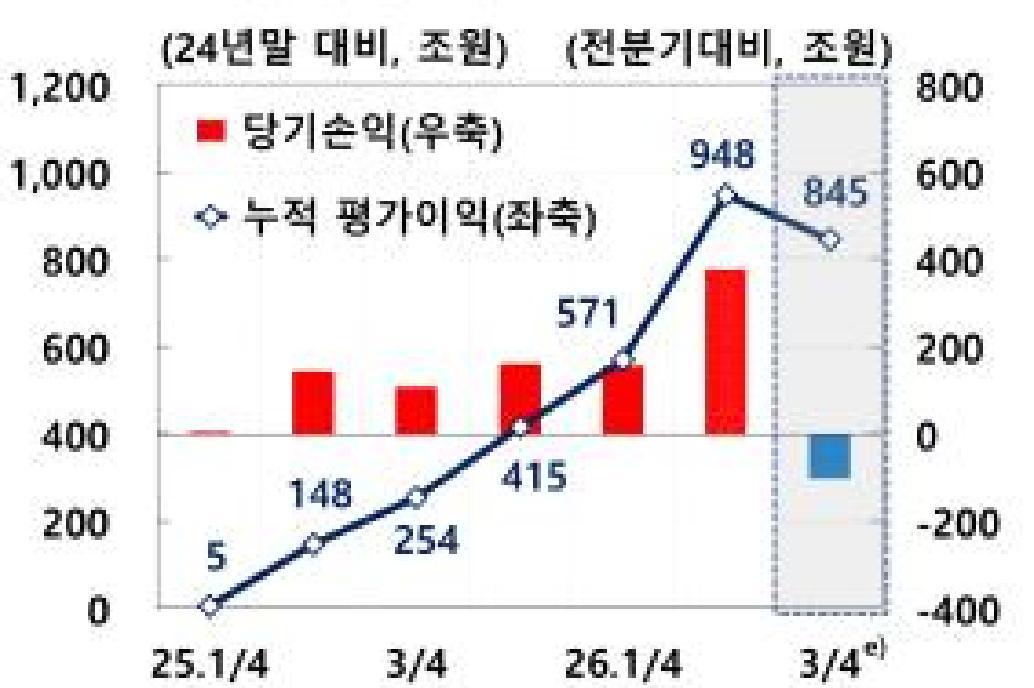

요약: 2024년 말 대비 조원 단위의 당기손익과 누적 평균이익을 나타내는 그래프. 빨간색 바는 당기손익을, 파란색 점선은 누적 평균이익을 표시하며, 주요 수치는 25.1/4, 26.1/4에 대한 변화를 보여줌.

이미지: figure-7-13.jpg


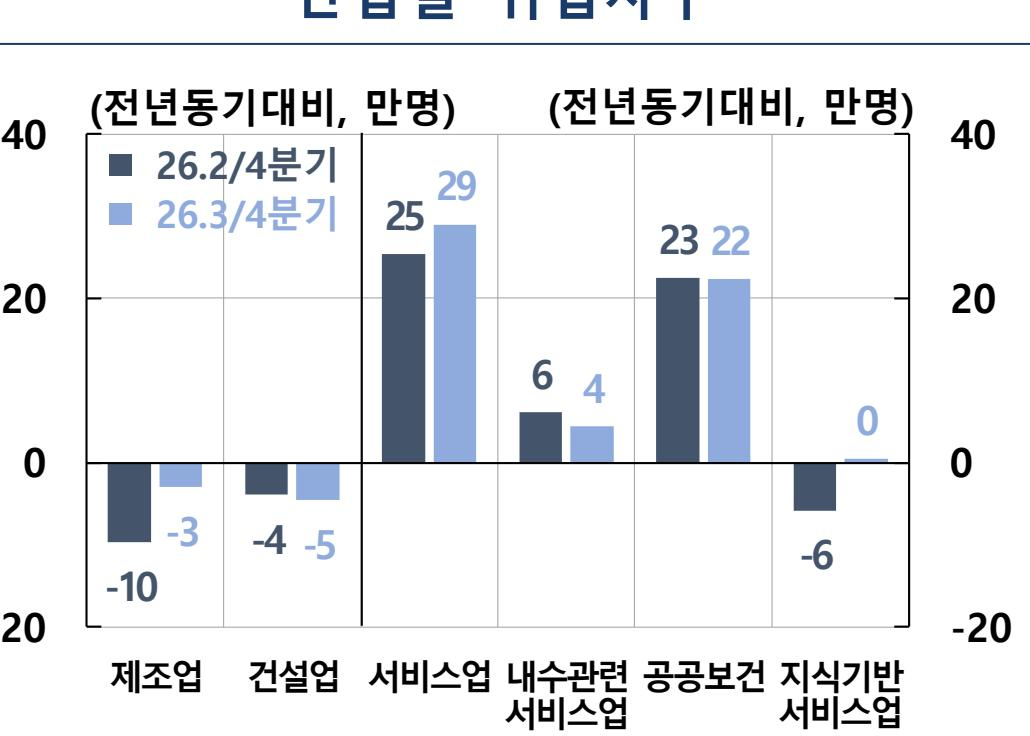

요약: 전년 동기 대비 변화율을 나타내는 그래프. 26.2/4분기와 26.3/4분기의 산업별 성과 비교. 제조업, 건설업, 서비스업, 공공부문, 지식 기반 서비스업의 수치 포함.



In [9]:
# 요약 품질 확인 ② 이미지: 그래프 이미지와 요약문을 나란히 확인
# (Before/After 질문의 근거가 된 그래프 포함)
for name in ["figure-16-39.jpg", "figure-7-13.jpg"]:
    idx = [f.name for f in image_files].index(name) if name in [f.name for f in image_files] else None
    if idx is None:
        continue
    print("=" * 60)
    print(f"이미지: {name}")
    print("=" * 60)
    display(Image(filename=str(image_files[idx]), width=450))
    print("요약:", image_summaries[idx])
    print()

### 2-5. 토큰 사용량 추정

In [10]:
# 텍스트 요약 토큰 사용량 (추정)
import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")
input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print(f"입력 : {input_tokens:,} 토큰")
print(f"출력 : {output_tokens:,} 토큰")
print(f"합계 : {input_tokens + output_tokens:,} 토큰")
print("요약한 이미지 수:", len(image_summaries), "장 (이미지 토큰은 해상도에 따라 달라 제외)")

입력 : 13,512 토큰
출력 : 4,851 토큰
합계 : 18,363 토큰
요약한 이미지 수: 41 장 (이미지 토큰은 해상도에 따라 달라 제외)


## 3. 다중 벡터 검색기
### 3-1. 벡터 DB · docstore 생성 및 요약-원본 색인

In [11]:
from langchain_classic.retrievers.multi_vector import MultiVectorRetriever
from langchain_core.stores import InMemoryStore
from langchain_core.documents import Document
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings

id_key = "doc_id"

vectorstore = Chroma(
    collection_name="multimodal_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
vectorstore.reset_collection()            # 재실행해도 이전 요약이 남지 않도록 비우기
store = InMemoryStore()
retriever = MultiVectorRetriever(vectorstore=vectorstore, docstore=store, id_key=id_key)


def add_documents(retriever, doc_summaries, doc_contents):
    """요약본은 벡터 DB에, 원본은 docstore에 '같은 id'로 저장합니다."""
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]
    summary_docs = [
        Document(page_content=s, metadata={id_key: doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]
    retriever.vectorstore.add_documents(summary_docs)               # 요약 → 벡터 DB
    retriever.docstore.mset(list(zip(doc_ids, doc_contents)))       # 원본 → docstore


if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)

print("색인 완료 — 벡터 DB에 저장된 요약 수:", len(vectorstore.get()["ids"]))

색인 완료 — 벡터 DB에 저장된 요약 수: 64


### 3-2. 검색 테스트

In [12]:
# 검색 테스트: 그래프를 봐야만 답할 수 있는 질문
query = "24년말 대비 26년 1분기의 누적 평가이익을 알려줘"
found = retriever.invoke(query)
print("검색된 원본 수:", len(found))
print()

BASE64_PATTERN = "^[A-Za-z0-9+/]{100,}={0,2}$"
for i, doc in enumerate(found):
    content = doc.page_content if hasattr(doc, "page_content") else doc
    kind = "이미지(Base64)" if re.match(BASE64_PATTERN, content) else "텍스트/표"
    print(f"[{i}] {kind} — 길이 {len(content):,}자")
    print("   ", content[:120].replace("\n", " "), "...")

검색된 원본 수: 4

[0] 이미지(Base64) — 길이 117,104자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...
[1] 이미지(Base64) — 길이 91,928자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...
[2] 이미지(Base64) — 길이 84,660자
    /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAxNDQ0Hyc5PTgyPC4zNDL/ ...
[3] 텍스트/표 — 길이 429자
    2025 (전년동기대비, %) 2024 연간 4/4 1/4 2/4 물 소비자물가 2.3 2.1 2.4 2.1 3.0 가 근원물가1) 2.2 1.9 2.0 2.2 2.4 경상수지(억$) 1,000 1,231 392 7 ...


### 3-3. 검색 결과를 이미지 / 텍스트로 분리

이미지: 3 건 / 텍스트(표 포함): 1 건


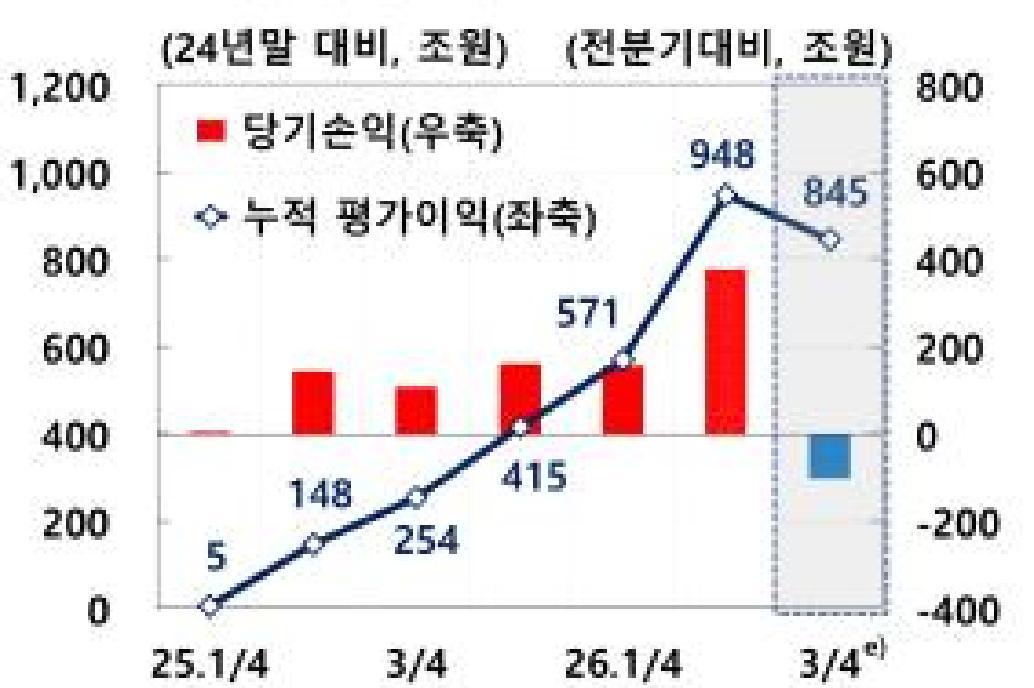

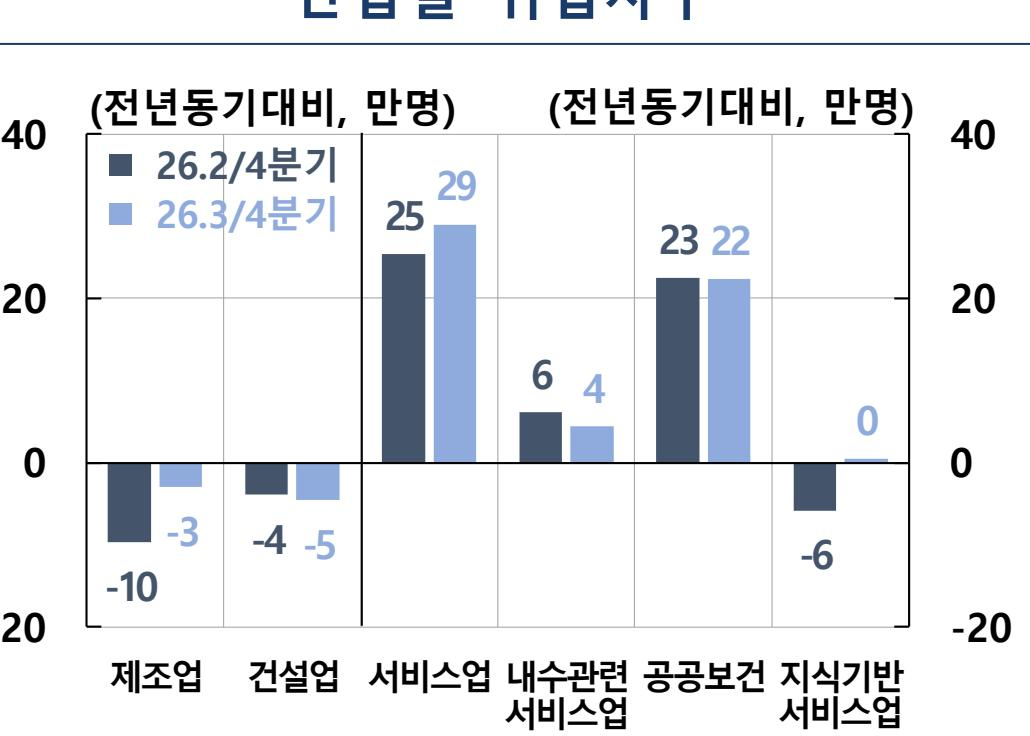

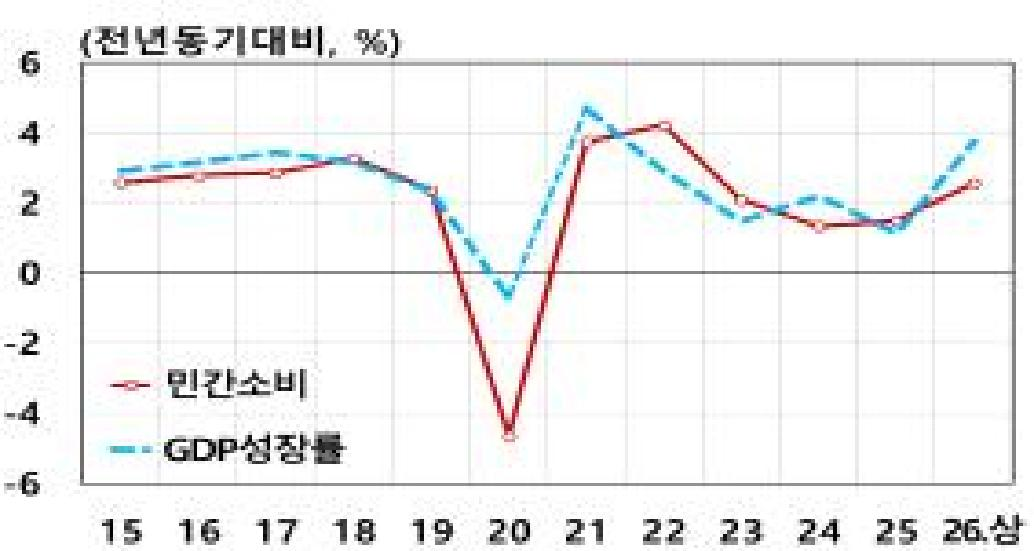

In [13]:
def split_image_text_types(docs):
    """검색 결과를 Base64 이미지와 텍스트(표 포함)로 나눕니다."""
    b64_images, texts_out = [], []
    for doc in docs:
        doc = doc.page_content if isinstance(doc, Document) else doc
        if re.match(BASE64_PATTERN, doc):
            b64_images.append(doc)
        else:
            texts_out.append(doc)
    return {"images": b64_images, "texts": texts_out}


split_data = split_image_text_types(found)
print("이미지:", len(split_data["images"]), "건 / 텍스트(표 포함):", len(split_data["texts"]), "건")

# 검색된 원본 이미지 확인 — LLM이 실제로 보게 되는 근거
for b64 in split_data["images"]:
    display(Image(data=base64.b64decode(b64), width=380))

## 4. 최종 멀티모달 체인
### 4-1. 프롬프트 조립 함수 · 체인 구성

In [14]:
from langchain_core.runnables import RunnableLambda, RunnablePassthrough


def img_prompt_func(data_dict):
    """검색된 원본을 멀티모달 LLM이 읽을 형태로 조립합니다."""
    messages = []
    for image in data_dict["context"]["images"]:          # 1. 이미지를 먼저
        messages.append({
            "type": "image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{image}"},
        })
    formatted_texts = "\n".join(data_dict["context"]["texts"])   # 2. 텍스트 + 질문
    messages.append({
        "type": "text",
        "text": (
            "자료를 근거로 질문에 한국어로 답하세요. 자료의 수치를 값과 단위까지 포함해서 일의 자리 이상부터 답변해주세요.\n"
            "자료에 없는 내용은 모른다고 답하세요.\n\n"
            f"질문: {data_dict['question']}\n\n"
            f"참고 텍스트:\n {formatted_texts}"
        ),
    })
    return [HumanMessage(content=messages)]


model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

multimodal_chain = (
    {
        "context": retriever | RunnableLambda(split_image_text_types),
        "question": RunnablePassthrough(),
    }
    | RunnableLambda(img_prompt_func)
    | model
    | StrOutputParser()
)
print("최종 체인 조립 완료")

최종 체인 조립 완료


### 4-2. 질의 실행

In [15]:
start = time.time()
answer = multimodal_chain.invoke(query)
print(f"답변 생성: {time.time() - start:.1f}초")
print("질문:", query)
print("-" * 60)
print(answer)

답변 생성: 2.9초
질문: 24년말 대비 26년 1분기의 누적 평가이익을 알려줘
------------------------------------------------------------
26년 1분기의 누적 평가이익은 571조 원입니다.


## 5. Before / After
### 5-1. 비교용 텍스트 전용 RAG 구성

In [16]:
text_vectorstore = Chroma(
    collection_name="text_only_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
text_vectorstore.reset_collection()
text_vectorstore.add_texts(texts_2k_token)
text_retriever = text_vectorstore.as_retriever(search_kwargs={"k": 4})

text_prompt = ChatPromptTemplate.from_template(
    "자료를 근거로 질문에 한국어로 답하세요\n"
    "그래프로 나타난 수치는 이미지를 분석하여 대략적인 값과 단위를 요약에 포함하세요\n"
    "자료에 없는 내용은 모른다고 답하세요.\n\n"
    "질문: {question}\n\n"
    "참고 텍스트 :\n {context}"
)


def format_docs(docs):
    return "\n".join(doc.page_content for doc in docs)


text_chain = (
    {
        "context": text_retriever | RunnableLambda(format_docs),
        "question": RunnablePassthrough(),
    }
    | text_prompt
    | model
    | StrOutputParser()
)
print("비교용 텍스트 전용 RAG 준비 완료")

비교용 텍스트 전용 RAG 준비 완료


### 5-2. 텍스트 전용 RAG vs 멀티모달 RAG 답변 비교

In [17]:
print("=" * 80)
print("질문:", query)
print("=" * 80)

before = text_chain.invoke(query)
print("\n[BEFORE] 텍스트 전용 RAG")
print("-" * 80)
print(before)

after = multimodal_chain.invoke(query)
print("\n[AFTER] 멀티모달 RAG")
print("-" * 80)
print(after)

질문: 24년말 대비 26년 1분기의 누적 평가이익을 알려줘

[BEFORE] 텍스트 전용 RAG
--------------------------------------------------------------------------------
제공된 자료에는 2024년 말 대비 2026년 1분기의 누적 평가이익에 대한 구체적인 수치나 정보가 포함되어 있지 않습니다. 따라서 해당 질문에 대한 답변을 드릴 수 없습니다.

[AFTER] 멀티모달 RAG
--------------------------------------------------------------------------------
26년 1분기의 누적 평가이익은 571조 원입니다.


## 6. 질의응답 5건
### 6-1. 질문 5개 실행

In [18]:
questions = [
    query,
    "이 문서의 핵심 주제를 한 문장으로 요약해줘",
    "문서에 나온 표의 내용을 설명해줘",
    "가장 중요한 수치 3가지를 알려줘",
    "이 문서가 다루지 않는 내용은 무엇인지 알려줘",
]

rows = []
for q in questions:
    kinds = split_image_text_types(retriever.invoke(q))
    ans = multimodal_chain.invoke(q)
    rows.append({
        "질문": q,
        "근거": f"이미지 {len(kinds['images'])}건 / 텍스트 {len(kinds['texts'])}건",
        "답변": ans,
    })
    print("=" * 70)
    print("Q:", q)
    print("근거:", rows[-1]["근거"])
    print("A:", ans[:400])
    print()

Q: 24년말 대비 26년 1분기의 누적 평가이익을 알려줘
근거: 이미지 3건 / 텍스트 1건
A: 26년 1분기의 누적 평가이익은 571조 원입니다.

Q: 이 문서의 핵심 주제를 한 문장으로 요약해줘
근거: 이미지 0건 / 텍스트 4건
A: 이 문서의 핵심 주제는 "최근 한국 경제의 민간소비 회복세가 반도체 경기 호조에도 불구하고 상대적으로 완만하며, 소비 증가 품목의 비중이 제한적이라는 점"입니다.

Q: 문서에 나온 표의 내용을 설명해줘
근거: 이미지 4건 / 텍스트 0건
A: 자료에 나온 표의 내용을 설명하겠습니다.

첫 번째 표는 특정 기간 동안의 수치를 나타내는 막대 그래프입니다. x축은 날짜를 나타내며, y축은 수치를 나타냅니다. 그래프에서 가장 높은 수치는 43으로 보이며, 이는 18일에 해당합니다. 19일과 24일도 비슷한 수치를 보이고 있습니다. 26일과 27일은 상대적으로 낮은 수치를 기록하고 있습니다.

두 번째 표는 회복 여건과 영향 시기를 나타내고 있습니다. 회복 여건은 세 가지 항목으로 나뉘며, 각각의 항목에 대해 영향 강도가 약, 중, 강으로 표시되어 있습니다. 첫 번째 항목인 '특별성 과급'은 강한 영향을 미치고 있으며, 두 번째 항목인 '정부 이전지출'은 약한 영향을 미치고 있습니다. 세 번째 항목인 '환율 하락'은 중간 정도의 영향을 미치고 있습니다.


Q: 가장 중요한 수치 3가지를 알려줘
근거: 이미지 4건 / 텍스트 0건
A: 1. 첫 번째 그래프에서 25일의 수치는 약 60입니다.
2. 두 번째 그래프에서 1분위의 비율은 50%입니다.
3. 세 번째 그래프에서 26.2/4분기의 제조업 기대비는 -10입니다.

Q: 이 문서가 다루지 않는 내용은 무엇인지 알려줘
근거: 이미지 2건 / 텍스트 2건
A: 이 문서가 다루지 않는 내용은 "배당소득이 없는 가구의 소비지출 변화"입니다. 문서에서는 배당소득이 있는 가구에 대한 소비지출 변화만을 다루고 있습니다.



### 6-2. README용 마크다운 표 출력

In [19]:
# README에 붙일 마크다운 표
print("| 질문 | 근거가 된 원본 (텍스트에는 표 포함) | 답변 |")
print("| --- | --- | --- |")
for r in rows:
    short = r["답변"].replace("\n", " ")[:120]
    print(f"| {r['질문']} | {r['근거']} | {short}... |")

| 질문 | 근거가 된 원본 (텍스트에는 표 포함) | 답변 |
| --- | --- | --- |
| 24년말 대비 26년 1분기의 누적 평가이익을 알려줘 | 이미지 3건 / 텍스트 1건 | 26년 1분기의 누적 평가이익은 571조 원입니다.... |
| 이 문서의 핵심 주제를 한 문장으로 요약해줘 | 이미지 0건 / 텍스트 4건 | 이 문서의 핵심 주제는 "최근 한국 경제의 민간소비 회복세가 반도체 경기 호조에도 불구하고 상대적으로 완만하며, 소비 증가 품목의 비중이 제한적이라는 점"입니다.... |
| 문서에 나온 표의 내용을 설명해줘 | 이미지 4건 / 텍스트 0건 | 자료에 나온 표의 내용을 설명하겠습니다.  첫 번째 표는 특정 기간 동안의 수치를 나타내는 막대 그래프입니다. x축은 날짜를 나타내며, y축은 수치를 나타냅니다. 그래프에서 가장 높은 수치는 43으로 보이며, 이는 ... |
| 가장 중요한 수치 3가지를 알려줘 | 이미지 4건 / 텍스트 0건 | 1. 첫 번째 그래프에서 25일의 수치는 약 60입니다. 2. 두 번째 그래프에서 1분위의 비율은 50%입니다. 3. 세 번째 그래프에서 26.2/4분기의 제조업 기대비는 -10입니다.... |
| 이 문서가 다루지 않는 내용은 무엇인지 알려줘 | 이미지 2건 / 텍스트 2건 | 이 문서가 다루지 않는 내용은 "배당소득이 없는 가구의 소비지출 변화"입니다. 문서에서는 배당소득이 있는 가구에 대한 소비지출 변화만을 다루고 있습니다.... |
